In [2]:
# Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.
# Determine the number of clusters using the elbow method.
# Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data

In [3]:
import pandas as pd
pd.set_option('display.max_columns', None)

In [4]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [5]:
df.sample(2)

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
819,10285,20,49.06,10,981.2,8/27/2004 0:00,Shipped,3,8,2004,Motorcycles,60,S18_2625,Marta's Replicas Co.,6175558555,39323 Spinnaker Dr.,NaN,Cambridge,MA,51247,USA,NaN,Hernandez,Marta,Small
1623,10193,20,50.62,9,1012.4,11/21/2003 0:00,Shipped,4,11,2003,Vintage Cars,44,S24_2022,"Australian Collectables, Ltd",61-9-3844-6555,7 Allen Street,NaN,Glen Waverly,Victoria,3150,Australia,APAC,Connery,Sean,Small


In [6]:
df.POSTALCODE.unique()

<StringArray>
[    '10022',     '51100',     '75508',     '90003',         nan,     '94217',
     '59000',    'N 5804',     '75016',      '3004',     '94019',     '97562',
     '44000',     '51247',     '21240',      '4110',     '70267',      '5020',
      '2067',     '50553',   'WX1 6LT',     '28034',  'S-958 22',     '28023',
     '79903',      '4101',     '71270',     '69004',   'V3F 2K1',     '97823',
  '106-0032',     '10100',  'S-844 67',     '78000',     '62005',     '58339',
      '2060',   'H1J 1C3',  '530-0003',     '24067',      '1734',   'WX3 6FW',
     '31000',   'WA1 1DP',      '8022',     '91217',    'B-1180',   'T2F 8M4',
     '51003',  'PO31 7PJ',     '90110',     '75012',      '8010',     '69045',
   '1227 MM',     '13008',     '50739',      '1203',     '42100',     '60528',
 'FIN-02271',         '2',   'EC2 5NT',      '8200',     '92561',     '41101',
     '67000',     '83030',    'N 0106',     '24100',      '3150',     '97561',
     '80686',    'B-6000']
Length: 74,

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [8]:
df = df.drop(["CONTACTLASTNAME","CONTACTFIRSTNAME","ORDERNUMBER","CUSTOMERNAME","PRODUCTCODE","PHONE","ADDRESSLINE1","ADDRESSLINE2","POSTALCODE"],axis=1)

In [9]:
df.sample(1)

,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,CITY,STATE,COUNTRY,TERRITORY,DEALSIZE
2276,45,75.63,7,3403.35,1/29/2003 0:00,Shipped,1,1,2003,Trucks and Buses,64,Stavern,NaN,Norway,EMEA,Medium


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   QUANTITYORDERED  2823 non-null   int64  
 1   PRICEEACH        2823 non-null   float64
 2   ORDERLINENUMBER  2823 non-null   int64  
 3   SALES            2823 non-null   float64
 4   ORDERDATE        2823 non-null   str    
 5   STATUS           2823 non-null   str    
 6   QTR_ID           2823 non-null   int64  
 7   MONTH_ID         2823 non-null   int64  
 8   YEAR_ID          2823 non-null   int64  
 9   PRODUCTLINE      2823 non-null   str    
 10  MSRP             2823 non-null   int64  
 11  CITY             2823 non-null   str    
 12  STATE            1337 non-null   str    
 13  COUNTRY          2823 non-null   str    
 14  TERRITORY        1749 non-null   str    
 15  DEALSIZE         2823 non-null   str    
dtypes: float64(2), int64(6), str(8)
memory usage: 353.0 KB


In [11]:
df.QTR_ID.unique()

array([1, 2, 3, 4])

In [12]:
# we only choose continuous data as k means doesnt understand other stuff

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore') # Keeps the elbow plot output clean

# 1. Select the most relevant numerical features for finding sales patterns
# We are ignoring QTR_ID/YEAR_ID because time clusters differently than financial metrics.
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = df[features]

# 2. Scale the data (Mandatory for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

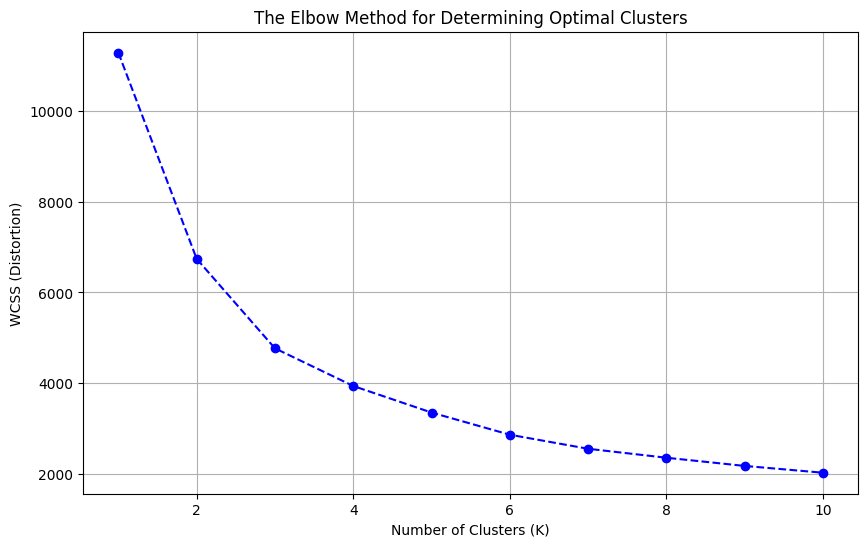

In [14]:
# 3. Calculate WCSS for different numbers of clusters (1 through 10)
wcss = []
for i in range(1, 11):
    # random_state=42 ensures you get the exact same clusters every time you run it
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_) # inertia_ is the WCSS score

# 4. Plot the Elbow Graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='b')
plt.title('The Elbow Method for Determining Optimal Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Distortion)')
plt.grid(True)
plt.show()

In [31]:
from sklearn.metrics import silhouette_score

# We start at 2 because you cannot calculate a silhouette score for 1 cluster
best_score = -1
optimal_k = 2

print("--- Silhouette Scores ---")
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    
    # Fit the data and get the cluster assignments
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    # Calculate the score
    score = silhouette_score(X_scaled, cluster_labels)
    print(f"Clusters: {k} | Score: {score:.4f}")
    
    # Keep track of the best score
    if score > best_score:
        best_score = score
        optimal_k = k

print(f"\n=> The optimal number of clusters is mathematically {optimal_k}")

--- Silhouette Scores ---
Clusters: 2 | Score: 0.3582
Clusters: 3 | Score: 0.3509
Clusters: 4 | Score: 0.3401
Clusters: 5 | Score: 0.3135
Clusters: 6 | Score: 0.3100
Clusters: 7 | Score: 0.3118
Clusters: 8 | Score: 0.2926
Clusters: 9 | Score: 0.2885
Clusters: 10 | Score: 0.2844

=> The optimal number of clusters is mathematically 2


In [16]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

X['KMeans_Cluster'] = clusters

print(X.head())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster
0               30      95.70  2871.00    95               0
1               34      81.35  2765.90    95               1
2               41      94.74  3884.34    95               0
3               45      83.26  3746.70    95               0
4               49     100.00  5205.27    95               0


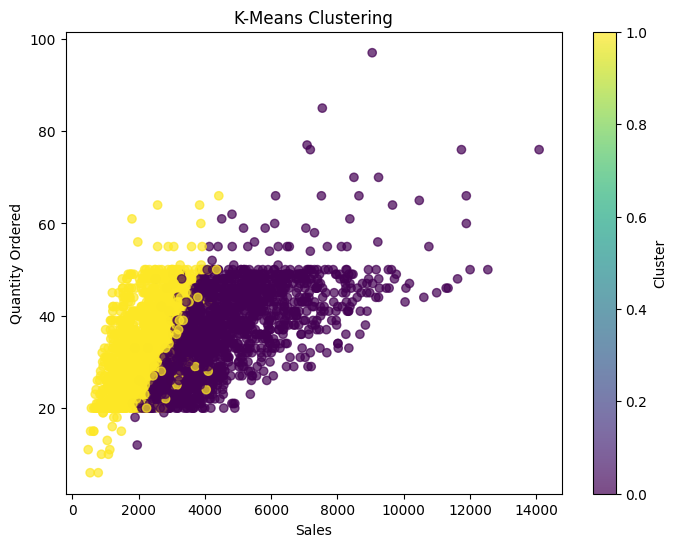

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X['SALES'],
    X['QUANTITYORDERED'],
    c=X['KMeans_Cluster'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.title("K-Means Clustering")
plt.colorbar(label="Cluster")
plt.show()

In [6]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

UnicodeDecodeError: 'utf-8' codec can't decode byte 0x84 in position 5327: invalid start byte

In [7]:
df.sample(2)

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
236,10381,20,100.00,1,2952.00,2/17/2005 0:00,Shipped,1,2,2005,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Small
754,10114,45,68.67,6,3090.15,4/1/2003 0:00,Shipped,2,4,2003,...,"265, boulevard Charonne",NaN,Paris,NaN,75012,France,EMEA,Bertrand,Marie,Medium
